In [2]:
import os 
import numpy as np
import cv2
from IPython.display import Video, display
import time
import imageio
from ipywidgets import interact, IntSlider, FloatSlider


root_path = './ecoco_depthmaps_test/train'
datapoints = []
    
for path in os.listdir(root_path):
    datapoints.append(( os.path.join(root_path, path, "flow"), 
                       os.path.join(root_path, path, "frames"),
                       os.path.join(root_path, path, "VoxelGrid-betweenframes-5") ))


In [44]:
flow, frames, voxels = datapoints[0]

In [59]:
print(flow)

./ecoco_depthmaps_test/train/sequence_0000000303/flow


In [60]:
output_path =  "video.mp4"
    
with imageio.get_writer(output_path, fps=5) as vid:
    for f in sorted(os.listdir(frames)):
        if f.endswith(".png"):
            im = imageio.imread(os.path.join(frames, f))
            vid.append_data(im[:,:])
        
display(Video(output_path, embed=True, width=600, height=400))

/tmp/ipykernel_26147/2309274834.py:6: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  im = imageio.imread(os.path.join(frames, f))
IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (240, 180) to (240, 192) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


In [61]:
boundary = os.path.join(flow, "boundary_timestamps.txt")
files = []
for el in sorted(os.listdir(flow)):
    if el.endswith(".npy"):
        files.append(os.path.join(flow, el))

a = np.load(files[0])

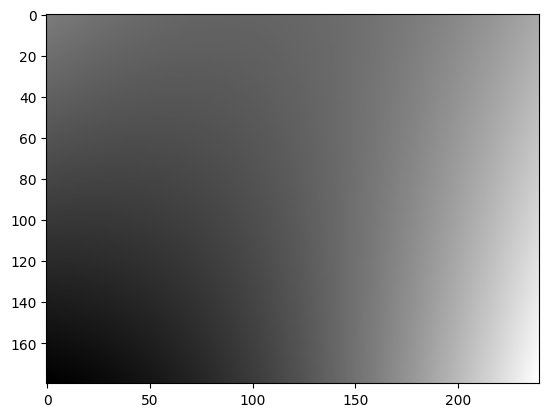

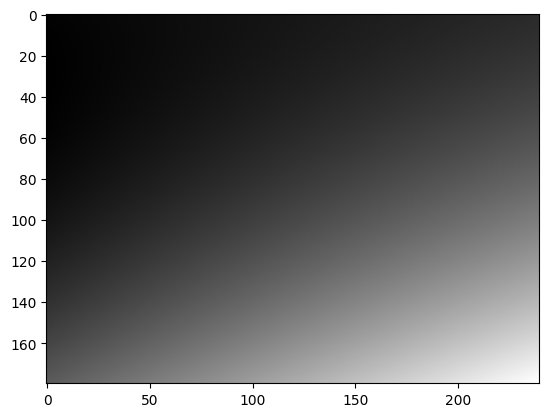

In [41]:
import matplotlib.pyplot as plt
plt.imshow(a[0], cmap='gray')
plt.show()

plt.imshow(a[1], cmap='gray')
plt.show()

In [63]:
boundary_voxels = os.path.join(voxels, "boundary_timestamps.txt")
files = []

for el in sorted(os.listdir(voxels)):
    if el.endswith(".npy"):
        files.append(os.path.join(voxels, el))

a = np.load(files[0])

In [65]:
a.shape

(5, 180, 240)

In [79]:
output_path =  "event_video.mp4"

frames = 0
with imageio.get_writer(output_path, fps=5) as vid:
    for f in sorted(os.listdir(voxels)):
        if f.endswith(".npy"):
            f = np.load(os.path.join(voxels, f))
            
            for i in range(f.shape[0]):
                frame = f[i, :, :]    
                im = 255 * (frame - np.min(frame)) / (np.max(frame) - np.min(frame))
                im = np.uint8(im)

                vid.append_data(im[:,:])
            
            frames += 1
            
        
            
print(frames)            
display(Video(output_path, embed=True, width=600, height=400))

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (240, 180) to (240, 192) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


58


# show both

In [ ]:
import os
import numpy as np
import imageio
from IPython.display import Video, display
from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets

# 1) Updated show_both to respect any i
def show_both(i, fps=5):
    """
    i   : index into datapoints
    fps : frames per second for output video
    """
    output_path = "video.mp4"
    flow, frames_dir, voxels_dir = datapoints[i]  # <-- use the slider index

    # load RGB frames
    rgb_images = []
    for fname in sorted(os.listdir(frames_dir)):
        if fname.endswith(".png"):
            rgb_images.append(imageio.imread(os.path.join(frames_dir, fname)))

    # load event / voxel frames
    events = []
    for fname in sorted(os.listdir(voxels_dir)):
        if fname.endswith(".npy"):
            arr = np.load(os.path.join(voxels_dir, fname))
            ev = []
            for k in range(arr.shape[0]):
                frame = arr[k]
                # normalize to 0–255
                im = 255 * (frame - frame.min()) / (frame.max() - frame.min())
                ev.append(np.uint8(im))
            events.append(np.stack(ev, axis=0))

    # write side-by-side video
    with imageio.get_writer(output_path, fps=fps) as vid:
        for rgb, event_stack in zip(rgb_images, events):
            for event_frame in event_stack:
                combined = np.hstack((rgb, event_frame))
                vid.append_data(combined)

    # embed
    return Video(output_path, embed=True)


# 2) Set up sliders using interact
max_index = len(datapoints) - 1

interact(show_both, i = IntSlider(min=0, max=max_index, step=1, value=0, description='Data Point Index'), fps = IntSlider(min=1, max=30, step=1, value=5, description='FPS'))

interactive(children=(IntSlider(value=0, description='Data Point Index', max=947), IntSlider(value=5, descript…

<function __main__.show_both(i, fps=5)>